In [1]:
import pandas as pd
from pathlib import Path

url = "https://datanemics.com/datasets/data/data-job-postings.csv"

df = pd.read_csv(url)

df.to_csv("../data/job_postings.csv", index=False)

print("Dataset downloaded and saved successfully!")

Dataset downloaded and saved successfully!


In [2]:
df.head()

,posting_id,posted_on,title,seniority,city,country,remote,salary_min_usd,salary_max_usd,company_size,skills
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,NaN,NaN,midmarket,python|dbt|airflow
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (3500, 11)

Column names:
['posting_id', 'posted_on', 'title', 'seniority', 'city', 'country', 'remote', 'salary_min_usd', 'salary_max_usd', 'company_size', 'skills']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   posting_id      3500 non-null   str    
 1   posted_on       3500 non-null   str    
 2   title           3500 non-null   str    
 3   seniority       3500 non-null   str    
 4   city            3500 non-null   str    
 5   country         3500 non-null   str    
 6   remote          3500 non-null   str    
 7   salary_min_usd  2738 non-null   float64
 8   salary_max_usd  2738 non-null   float64
 9   company_size    3500 non-null   str    
 10  skills          3500 non-null   str    
dtypes: float64(2), str(9)
memory usage: 629.2 KB


In [4]:
missing_values = df.isnull().sum()

print(missing_values)

posting_id          0
posted_on           0
title               0
seniority           0
city                0
country             0
remote              0
salary_min_usd    762
salary_max_usd    762
company_size        0
skills              0
dtype: int64


In [5]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [26]:
top_titles = df["title"].value_counts().head(10)

display(top_titles)

title
Data Analyst                 307
Senior Data Analyst          270
Data Engineer                252
Junior Data Analyst          206
Senior Data Engineer         198
Data Scientist               182
Senior Data Scientist        169
Junior Data Engineer         144
Senior Analytics Engineer    136
Analytics Engineer           131
Name: count, dtype: int64

In [7]:
top_cities = df["city"].value_counts().head(10)

display(top_cities)

city
San Francisco    532
New York         495
London           436
Bengaluru        417
Berlin           333
Chicago          299
Austin           253
Toronto          247
Amsterdam        245
São Paulo        243
Name: count, dtype: int64

In [8]:
salary_columns = [
    col for col in df.columns
    if "salary" in col.lower()
]

print("Salary columns:", salary_columns)

display(df[salary_columns].describe())

Salary columns: ['salary_min_usd', 'salary_max_usd']


,salary_min_usd,salary_max_usd
count,2738.000000,2738.000000
mean,104106.281958,138806.975895
std,50769.146511,67697.145049
min,17000.000000,22500.000000
25%,66500.000000,89000.000000
50%,98000.000000,131000.000000
75%,133500.000000,178000.000000
max,307000.000000,409000.000000


In [9]:
print(df.columns.tolist())

['posting_id', 'posted_on', 'title', 'seniority', 'city', 'country', 'remote', 'salary_min_usd', 'salary_max_usd', 'company_size', 'skills']


In [10]:
display(df["skills"].head(10))

0           looker|excel|statistics|tableau|sql
1        statistics|looker|excel|python|tableau
2                            python|dbt|airflow
3                        python|aws|sql|pytorch
4              modelling|power bi|sql|excel|dax
5                   excel|looker|python|tableau
6           tableau|statistics|python|excel|sql
7             kubernetes|aws|pytorch|python|sql
8                   aws|observability|terraform
9    sql|python|looker|statistics|excel|tableau
Name: skills, dtype: str

In [20]:
all_skills = df["skills"].dropna().str.split("|").explode()

all_skills = all_skills.str.strip().str.lower()

top_skills = all_skills.value_counts().head(10)

display(top_skills)

skills
sql           2350
python        2344
statistics    1204
excel          893
aws            830
airflow        778
pytorch        722
looker         694
tableau        666
terraform      617
Name: count, dtype: int64

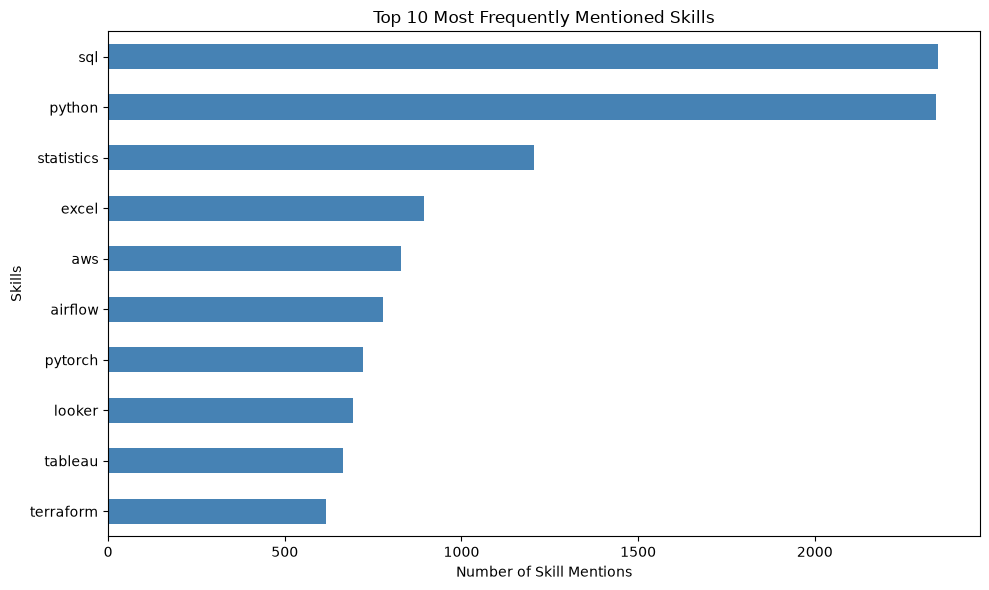

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

top_skills.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Most Frequently Mentioned Skills")
plt.xlabel("Number of Skill Mentions")
plt.ylabel("Skills")

plt.tight_layout()
plt.show()

In [6]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean.columns = df_clean.columns.str.strip()

text_columns = df_clean.select_dtypes(include=["object", "str"]).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original rows: 3500
Cleaned rows: 3500
Remaining duplicate rows: 0


In [7]:
df_clean.to_csv("../data/cleaned_job_postings.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [8]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd

df = pd.read_csv("../data/job_postings.csv")
df_clean = pd.read_csv("../data/cleaned_job_postings.csv")

print("Dataset reloaded successfully!")
print("Rows:", len(df_clean))

Dataset reloaded successfully!
Rows: 3500


In [10]:
import mysql.connector

print("MySQL connector is ready!")

MySQL connector is ready!


In [38]:
import mysql.connector
from getpass import getpass

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password=getpass("Enter MySQL password: ")
)

print("Connected to MySQL successfully!")

Enter MySQL password:  ········


Connected to MySQL successfully!


In [12]:
cursor = conn.cursor()

cursor.execute(
    "CREATE DATABASE IF NOT EXISTS job_market_analyzer"
)

print("Database created successfully!")

Database created successfully!


In [13]:
conn.database = "job_market_analyzer"

cursor = conn.cursor()
cursor.execute("SELECT DATABASE()")

print("Connected database:", cursor.fetchone()[0])

Connected database: job_market_analyzer


In [6]:
%pip install sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [40]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus
from getpass import getpass

mysql_user = "root"
mysql_password = getpass("Enter your MySQL password: ")

engine = create_engine(
    f"mysql+mysqlconnector://{mysql_user}:{quote_plus(mysql_password)}"
    "@localhost/job_market_analyzer"
)

df_clean.to_sql(
    name="job_postings",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=500
)

print("Dataset imported into MySQL successfully!")

Enter your MySQL password:  ········


Dataset imported into MySQL successfully!


In [8]:
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM job_postings")
row_count = cursor.fetchone()[0]

print("Rows in MySQL:", row_count)

Rows in MySQL: 3500


In [9]:
query = """
SELECT title, COUNT(*) AS job_count
FROM job_postings
GROUP BY title
ORDER BY job_count DESC
LIMIT 10;
"""

cursor.execute(query)

results = cursor.fetchall()

for title, count in results:
    print(f"{title}: {count}")

Data Analyst: 307
Senior Data Analyst: 270
Data Engineer: 252
Junior Data Analyst: 206
Senior Data Engineer: 198
Data Scientist: 182
Senior Data Scientist: 169
Junior Data Engineer: 144
Senior Analytics Engineer: 136
Analytics Engineer: 131


In [15]:
query = """
SELECT city, COUNT(*) AS job_count
FROM job_postings
GROUP BY city
ORDER BY job_count DESC
LIMIT 10;
"""

cursor.execute(query)

results = cursor.fetchall()

for city, count in results:
    print(f"{city}: {count}")

San Francisco: 532
New York: 495
London: 436
Bengaluru: 417
Berlin: 333
Chicago: 299
Austin: 253
Toronto: 247
Amsterdam: 245
São Paulo: 243


In [16]:
query = """
WITH RECURSIVE skill_split AS (
    SELECT
        TRIM(SUBSTRING_INDEX(skills, '|', 1)) AS skill,
        SUBSTRING(
            skills,
            LENGTH(SUBSTRING_INDEX(skills, '|', 1)) + 2
        ) AS remaining
    FROM job_postings
    WHERE skills IS NOT NULL AND skills <> ''

    UNION ALL

    SELECT
        TRIM(SUBSTRING_INDEX(remaining, '|', 1)),
        CASE
            WHEN remaining LIKE '%|%'
            THEN SUBSTRING(remaining, LENGTH(SUBSTRING_INDEX(remaining, '|', 1)) + 2)
            ELSE ''
        END
    FROM skill_split
    WHERE remaining <> ''
)
SELECT LOWER(skill) AS skill, COUNT(*) AS mentions
FROM skill_split
WHERE skill <> ''
GROUP BY LOWER(skill)
ORDER BY mentions DESC
LIMIT 10;
"""

cursor.execute(query)

for skill, mentions in cursor.fetchall():
    print(f"{skill}: {mentions}")

sql: 2350
python: 2344
statistics: 1204
excel: 893
aws: 830
airflow: 778
pytorch: 722
looker: 694
tableau: 666
terraform: 617


In [12]:
cursor.execute("DESCRIBE job_postings")

for column in cursor.fetchall():
    print(column[0], "|", column[1])

posting_id | text
posted_on | text
title | text
seniority | text
city | text
country | text
remote | text
salary_min_usd | double
salary_max_usd | double
company_size | text
skills | text


In [17]:
query = """
SELECT
    title,
    ROUND(AVG((salary_min_usd + salary_max_usd) / 2), 2)
        AS average_salary_usd,
    COUNT(*) AS job_count
FROM job_postings
WHERE salary_min_usd IS NOT NULL
  AND salary_max_usd IS NOT NULL
GROUP BY title
HAVING COUNT(*) >= 10
ORDER BY average_salary_usd DESC
LIMIT 10;
"""

cursor.execute(query)

results = cursor.fetchall()

for title, salary, count in results:
    print(
        f"{title}: ${salary:,.2f} "
        f"(based on {count} listings)"
    )

Lead Machine Learning Engineer: $255,416.67 (based on 27 listings)
Staff Machine Learning Engineer: $229,488.64 (based on 22 listings)
Lead Data Platform Engineer: $213,600.00 (based on 15 listings)
Lead Data Scientist: $207,910.00 (based on 25 listings)
Staff Data Scientist: $205,635.14 (based on 37 listings)
Lead Data Engineer: $202,202.38 (based on 42 listings)
Staff Data Platform Engineer: $198,897.73 (based on 22 listings)
Staff Data Engineer: $175,820.65 (based on 46 listings)
Lead Analytics Engineer: $175,694.44 (based on 18 listings)
Senior Research Scientist: $174,500.00 (based on 18 listings)


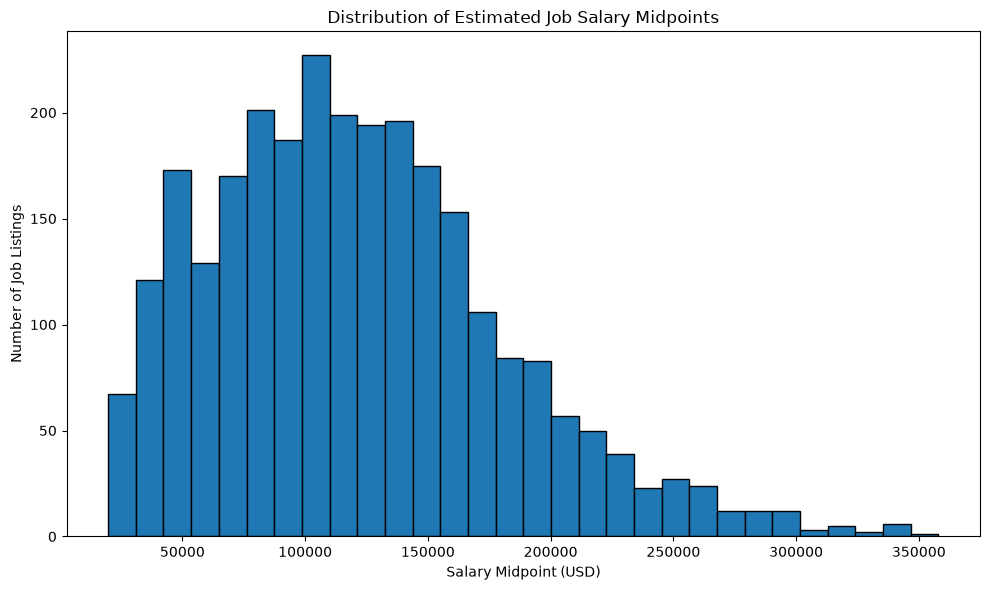

In [22]:
salary_df = df_clean.dropna(
    subset=["salary_min_usd", "salary_max_usd"]
).copy()

salary_df["salary_midpoint_usd"] = (
    salary_df["salary_min_usd"] + salary_df["salary_max_usd"]
) / 2

plt.figure(figsize=(10, 6))

plt.hist(
    salary_df["salary_midpoint_usd"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Estimated Job Salary Midpoints")
plt.xlabel("Salary Midpoint (USD)")
plt.ylabel("Number of Job Listings")

plt.tight_layout()
plt.show()

In [23]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


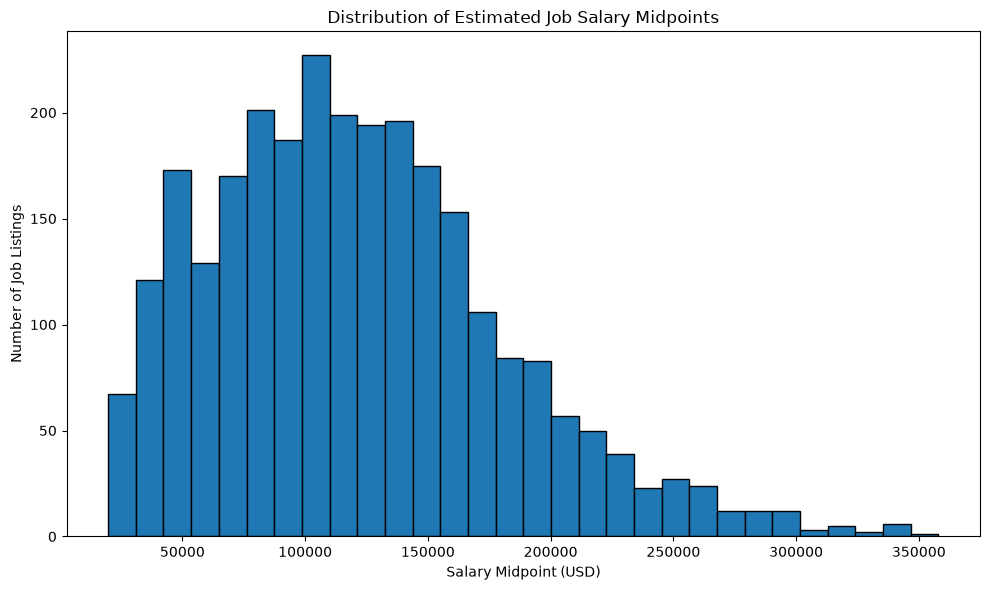

Salary chart saved successfully!


In [24]:
from pathlib import Path

Path("../outputs").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

plt.hist(
    salary_df["salary_midpoint_usd"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Estimated Job Salary Midpoints")
plt.xlabel("Salary Midpoint (USD)")
plt.ylabel("Number of Job Listings")

plt.tight_layout()
plt.savefig("../outputs/salary_distribution.png", dpi=150)
plt.show()

print("Salary chart saved successfully!")

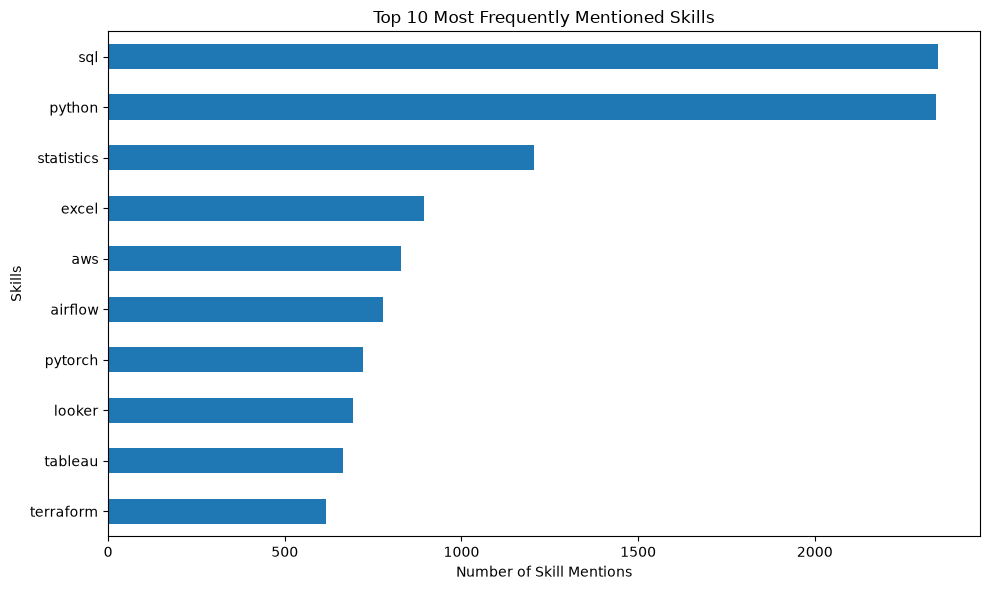

Skills chart saved successfully!


In [20]:
plt.figure(figsize=(10, 6))

top_skills.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Most Frequently Mentioned Skills")
plt.xlabel("Number of Skill Mentions")
plt.ylabel("Skills")

plt.tight_layout()
plt.savefig("../outputs/top_skills.png", dpi=150)
plt.show()

print("Skills chart saved successfully!")

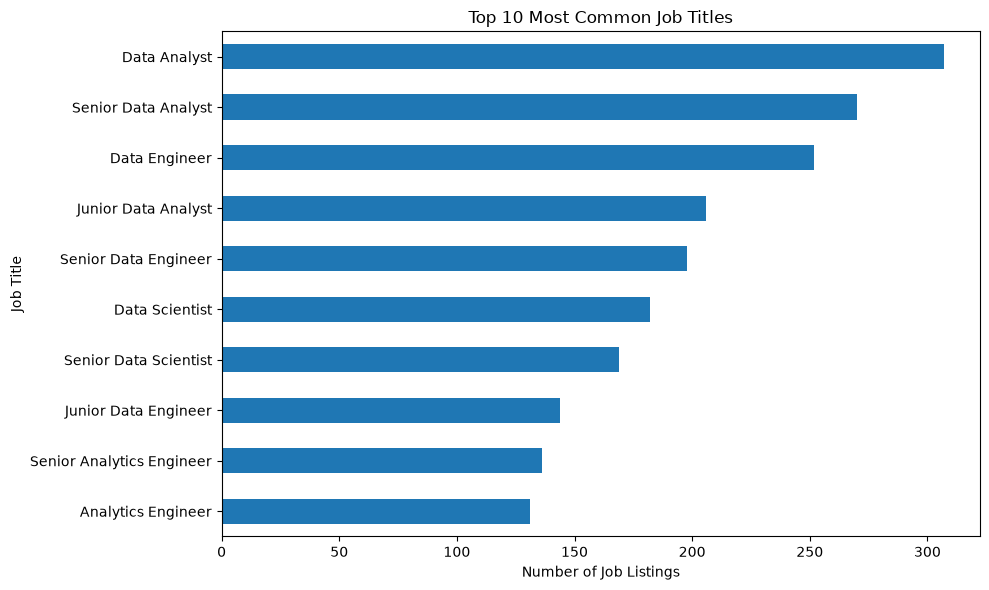

Job title chart saved successfully!


In [27]:
plt.figure(figsize=(10, 6))

top_titles.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Most Common Job Titles")
plt.xlabel("Number of Job Listings")

plt.ylabel("Job Title")

plt.tight_layout()
plt.savefig("../outputs/top_job_titles.png", dpi=150)
plt.show()

print("Job title chart saved successfully!")

In [27]:
top_titles = df_clean["title"].value_counts().head(10)

display(top_titles)

title
Data Analyst                 307
Senior Data Analyst          270
Data Engineer                252
Junior Data Analyst          206
Senior Data Engineer         198
Data Scientist               182
Senior Data Scientist        169
Junior Data Engineer         144
Senior Analytics Engineer    136
Analytics Engineer           131
Name: count, dtype: int64

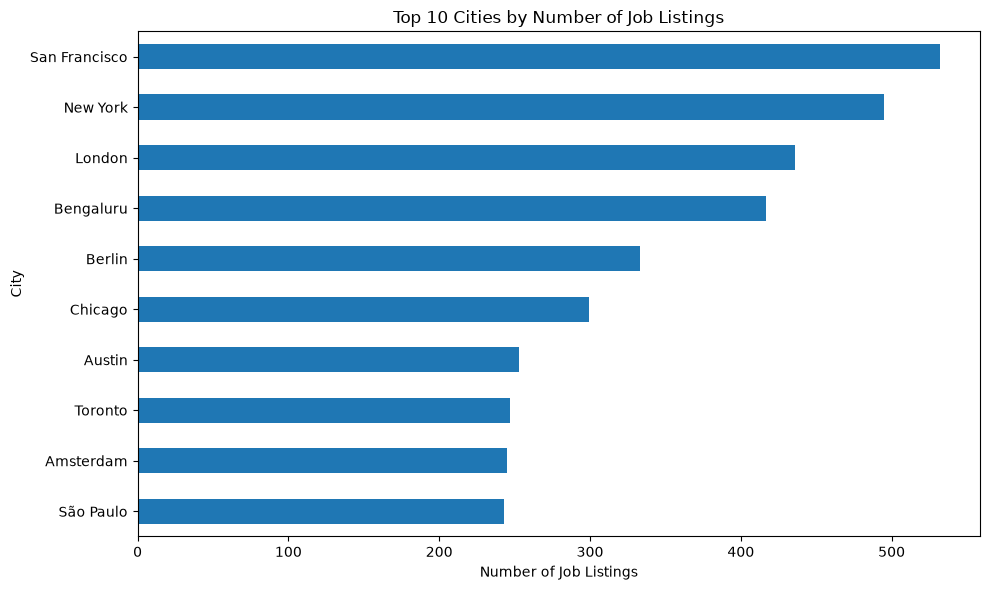

City chart saved successfully!


In [29]:
top_cities = df_clean["city"].value_counts().head(10)

plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Number of Job Listings")
plt.xlabel("Number of Job Listings")
plt.ylabel("City")

plt.tight_layout()
plt.savefig("../outputs/top_cities.png", dpi=150)
plt.show()

print("City chart saved successfully!")

In [30]:
# Generate project summary
summary = {
    "Total job listings": len(df_clean),
    "Unique job titles": df_clean["title"].nunique(),
    "Unique cities": df_clean["city"].nunique(),
    "Unique countries": df_clean["country"].nunique(),
    "Listings with salary data": df_clean[
        ["salary_min_usd", "salary_max_usd"]
    ].dropna().shape[0],
    "Unique skills": all_skills.nunique()
}

for metric, value in summary.items():
    print(f"{metric}: {value}")

Total job listings: 3500
Unique job titles: 40
Unique cities: 10
Unique countries: 7
Listings with salary data: 2738
Unique skills: 25


In [31]:
summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

summary_df.to_csv(
    "../outputs/project_summary.csv",
    index=False
)

display(summary_df)

print("Project summary saved successfully!")

,Metric,Value
0,Total job listings,3500
1,Unique job titles,40
2,Unique cities,10
3,Unique countries,7
4,Listings with salary data,2738
5,Unique skills,25


Project summary saved successfully!


In [32]:
%%writefile ../requirements.txt
streamlit
pandas
numpy
matplotlib
plotly
seaborn
mysql-connector-python
SQLAlchemy
scikit-learn

Writing ../requirements.txt


In [33]:
%%writefile ../README.md

A Python data analysis project that explores job listings,
skill mentions, locations, and salary ranges.

The dataset used in this project is synthetic and is intended
for learning and demonstration purposes.

## Features
- Data inspection and cleaning with Pandas
- Job title and location analysis
- Skill frequency analysis
- Salary range analysis
- SQL analysis using MySQL
- Visualizations using Matplotlib
- Exportable summary metrics

## Technologies
- Python
- Pandas and NumPy
- MySQL
- Matplotlib
- JupyterLab

## Project Structure
- data/: Raw and cleaned datasets
- notebooks/: Analysis notebook
- outputs/: Charts and summary CSV

## Outputs
- Top skills chart
- Top job titles chart
- Top cities chart
- Salary distribution chart
- Project summary CSV

## Limitations
The dataset is synthetic, so the results do not represent
actual job market demand or real-world salary benchmarks.

## Author
Add Anik Khanra

Writing ../README.md


In [34]:
from pathlib import Path
import pandas as pd

files_to_check = [
    "../data/job_postings.csv",
    "../data/cleaned_job_postings.csv",
    "../outputs/top_skills.png",
    "../outputs/top_job_titles.png",
    "../outputs/top_cities.png",
    "../outputs/salary_distribution.png",
    "../outputs/project_summary.csv",
    "../requirements.txt",
    "../README.md"
]

for file in files_to_check:
    status = "FOUND" if Path(file).exists() else "MISSING"
    print(f"{status}: {file}")

df_check = pd.read_csv("../data/cleaned_job_postings.csv")

print("\nCleaned dataset rows:", len(df_check))
print("Cleaned dataset columns:", len(df_check.columns))

FOUND: ../data/job_postings.csv
FOUND: ../data/cleaned_job_postings.csv
FOUND: ../outputs/top_skills.png
FOUND: ../outputs/top_job_titles.png
FOUND: ../outputs/top_cities.png
FOUND: ../outputs/salary_distribution.png
FOUND: ../outputs/project_summary.csv
FOUND: ../requirements.txt
FOUND: ../README.md

Cleaned dataset rows: 3500
Cleaned dataset columns: 11


In [35]:
print(df_clean.columns.tolist())

display(df_clean["title"].head(15))

print("Unique job titles:", df_clean["title"].nunique())

['posting_id', 'posted_on', 'title', 'seniority', 'city', 'country', 'remote', 'salary_min_usd', 'salary_max_usd', 'company_size', 'skills']


0                  Junior Data Analyst
1                         Data Analyst
2                   Analytics Engineer
3     Senior Machine Learning Engineer
4                  Junior BI Developer
5                         Data Analyst
6                  Junior Data Analyst
7     Senior Machine Learning Engineer
8        Junior Data Platform Engineer
9                  Senior Data Analyst
10           Junior Research Scientist
11                 Junior Data Analyst
12                 Junior Data Analyst
13                 Senior Data Analyst
14     Staff Machine Learning Engineer
Name: title, dtype: str

Unique job titles: 40


In [36]:
def categorize_job(title):
    title = title.lower()

    if "machine learning" in title:
        return "Machine Learning"

    elif "research scientist" in title:
        return "Research"

    elif "bi developer" in title or "business intelligence" in title:
        return "Business Intelligence"

    elif "data platform" in title or "analytics engineer" in title:
        return "Data Engineering"

    elif "analyst" in title:
        return "Data Analytics"

    else:
        return "Other"


df_ml = df_clean.copy()
df_ml["job_category"] = df_ml["title"].apply(categorize_job)

display(df_ml[["title", "job_category"]].head(15))

print("\nCategory counts:")
display(df_ml["job_category"].value_counts())

,title,job_category
0,Junior Data Analyst,Data Analytics
1,Data Analyst,Data Analytics
2,Analytics Engineer,Data Engineering
3,Senior Machine Learning Engineer,Machine Learning
4,Junior BI Developer,Business Intelligence
5,Data Analyst,Data Analytics
6,Junior Data Analyst,Data Analytics
7,Senior Machine Learning Engineer,Machine Learning
8,Junior Data Platform Engineer,Data Engineering
9,Senior Data Analyst,Data Analytics



Category counts:


job_category
Other                    1254
Data Analytics            924
Data Engineering          654
Machine Learning          304
Business Intelligence     267
Research                   97
Name: count, dtype: int64

In [37]:
category_counts = df_ml["job_category"].value_counts()

display(category_counts)

print("\nNumber of uncategorized jobs:",
      (df_ml["job_category"] == "Other").sum())

job_category
Other                    1254
Data Analytics            924
Data Engineering          654
Machine Learning          304
Business Intelligence     267
Research                   97
Name: count, dtype: int64


Number of uncategorized jobs: 1254


In [38]:
display(df_ml["job_category"].value_counts())

display(
    df_ml.loc[
        df_ml["job_category"] == "Other",
        ["title", "job_category"]
    ]["title"].value_counts()
)

job_category
Other                    1254
Data Analytics            924
Data Engineering          654
Machine Learning          304
Business Intelligence     267
Research                   97
Name: count, dtype: int64

title
Data Engineer            252
Senior Data Engineer     198
Data Scientist           182
Senior Data Scientist    169
Junior Data Engineer     144
Junior Data Scientist    118
Staff Data Engineer       61
Lead Data Engineer        52
Staff Data Scientist      42
Lead Data Scientist       36
Name: count, dtype: int64

In [39]:
from sklearn.model_selection import train_test_split

# Input feature: job title
X = df_ml["title"].fillna("")

# Target: category created in Step 38
y = df_ml["job_category"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Data preparation complete!")

Training samples: 2800
Testing samples: 700
Data preparation complete!


In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Text vectorization complete!")

Training matrix shape: (2800, 45)
Testing matrix shape: (700, 45)
Text vectorization complete!


In [41]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training complete!")

Model training complete!


In [42]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model accuracy: 100.00%

Classification Report:
                       precision    recall  f1-score   support

Business Intelligence       1.00      1.00      1.00        53
       Data Analytics       1.00      1.00      1.00       185
     Data Engineering       1.00      1.00      1.00       131
     Machine Learning       1.00      1.00      1.00        61
                Other       1.00      1.00      1.00       251
             Research       1.00      1.00      1.00        19

             accuracy                           1.00       700
            macro avg       1.00      1.00      1.00       700
         weighted avg       1.00      1.00      1.00       700



In [43]:
import joblib
from pathlib import Path

Path("../outputs").mkdir(parents=True, exist_ok=True)

joblib.dump(model, "../outputs/job_category_model.pkl")

joblib.dump(vectorizer, "../outputs/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [44]:
import joblib

loaded_model = joblib.load("../outputs/job_category_model.pkl")
loaded_vectorizer = joblib.load("../outputs/tfidf_vectorizer.pkl")

new_title = ["Senior Data Analyst"]

new_title_tfidf = loaded_vectorizer.transform(new_title)

prediction = loaded_model.predict(new_title_tfidf)

print("Job title:", new_title[0])
print("Predicted category:", prediction[0])

Job title: Senior Data Analyst
Predicted category: Data Analytics


In [45]:
from pathlib import Path

files_to_check = [
    "../data/job_postings.csv",
    "../data/cleaned_job_postings.csv",
    "../outputs/top_skills.png",
    "../outputs/top_job_titles.png",
    "../outputs/top_cities.png",
    "../outputs/salary_distribution.png",
    "../outputs/project_summary.csv",
    "../outputs/job_category_model.pkl",
    "../outputs/tfidf_vectorizer.pkl",
    "../requirements.txt",
    "../README.md"
]

for file in files_to_check:
    status = "FOUND" if Path(file).exists() else "MISSING"
    print(f"{status}: {file}")

FOUND: ../data/job_postings.csv
FOUND: ../data/cleaned_job_postings.csv
FOUND: ../outputs/top_skills.png
FOUND: ../outputs/top_job_titles.png
FOUND: ../outputs/top_cities.png
FOUND: ../outputs/salary_distribution.png
FOUND: ../outputs/project_summary.csv
FOUND: ../outputs/job_category_model.pkl
FOUND: ../outputs/tfidf_vectorizer.pkl
FOUND: ../requirements.txt
FOUND: ../README.md


In [46]:
%%writefile -a ../README.md

A basic job-title classifier built using scikit-learn.

1. Create broad job categories from job titles using simple rules.
2. Split the dataset into training and testing sets.
3. Convert job titles into TF-IDF features.
4. Train a Logistic Regression classifier.
5. Evaluate predictions using accuracy, precision, recall, and F1-score.
6. Save the trained model and TF-IDF vectorizer with joblib.

- outputs/job_category_model.pkl
- outputs/tfidf_vectorizer.pkl

The categories were generated using title-based rules. The model
therefore learns to reproduce those rules, rather than learning
independently verified job classifications. The dataset is synthetic,
so the results should not be interpreted as real-world job-market insights.

Appending to ../README.md


In [30]:
pip install streamlit pandas

Note: you may need to restart the kernel to use updated packages.


In [ ]:
!streamlit run "C:\Users\User\OneDrive\Desktop\job-market-analyzer\app.py"

In [ ]:
from pathlib import Path

print(Path(".gitignore").exists())

In [35]:
import os
from pathlib import Path

print("Current directory:", os.getcwd())
print("Gitignore exists:", Path(".gitignore").exists())

Current directory: C:\Users\User\OneDrive\Desktop\job-market-analyzer\notebooks
Gitignore exists: False


In [36]:
from pathlib import Path

project_path = Path("..")

print("Gitignore exists:", (project_path / ".gitignore").exists())

Gitignore exists: True
